# TA-03 Data-Driven Monte Carlo Simulation
**Mata Praktikum:** Pemodelan dan Simulasi · **Semester:** 5
**Nama:** Muhammad Fadillah Ramadhan · **NIM:** 301240051

**Topik (digit terakhir NIM = 1):** Forecasting Harga Saham
**Pertanyaan:** Berapa probabilitas harga saham turun lebih dari 10% dalam 30 hari ke depan?

**Alur:** Load data Kaggle → Cleaning → Ekstraksi parameter (μ, σ) → Simulasi Monte Carlo (≥ 5.000 jalur) → Analisis risiko → Kesimpulan.

## 1. Import Library & Konfigurasi

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

NIM = 301240051
np.random.seed(NIM)          # seed = NIM agar hasil konsisten

# ---- Konfigurasi ----
CSV_PATH    = "data/TSLA.csv"   # ganti dengan file dataset Kaggle (Apple / Tesla / BCA)
PRICE_COL   = None              # None = otomatis cari 'Adj Close' / 'Close'
HORIZON     = 30                # hari ke depan
N_SIM       = 10_000            # jumlah skenario (minimal 5.000)
DROP_THRESH = 0.10              # batas penurunan 10%

## 2. Load Data Kaggle
Contoh dataset: *Tesla Stock Price* / *Apple Stock Price History* / *BBCA Stock Price* di Kaggle.
Unduh manual lalu letakkan CSV di folder `data/`, atau (opsional) pakai `kagglehub`:
```python
# import kagglehub
# path = kagglehub.dataset_download("<owner>/<nama-dataset>")
```

In [2]:
df = pd.read_csv(CSV_PATH)
print("Kolom:", list(df.columns))
df.head()

Kolom: ['Date', 'High', 'Low', 'Open', 'Close', 'Volume', 'Adj Close']


,Date,High,Low,Open,Close,Volume,Adj Close
0,2019-09-30,48.796001,47.222000,48.599998,48.174000,29399000.0,48.174000
1,2019-10-01,49.189999,47.826000,48.299999,48.938000,30813000.0,48.938000
2,2019-10-02,48.930000,47.886002,48.658001,48.625999,28157000.0,48.625999
3,2019-10-03,46.896000,44.855999,46.372002,46.605999,75422500.0,46.605999
4,2019-10-04,46.956001,45.613998,46.321999,46.285999,39975000.0,46.285999


## 3. Data Cleaning

In [3]:
# Tentukan kolom tanggal & harga
date_col = next((c for c in df.columns if c.lower() in ("date", "tanggal")), None)
if PRICE_COL is None:
    for cand in ("adj close", "adj_close", "close", "close/last", "price"):
        m = [c for c in df.columns if c.lower() == cand]
        if m:
            PRICE_COL = m[0]; break
print("Kolom harga yang dipakai:", PRICE_COL)

# Harga bisa berformat teks (mis. '$1,234.50')
df[PRICE_COL] = pd.to_numeric(df[PRICE_COL].astype(str).str.replace(r"[$,\s]", "", regex=True), errors="coerce")

if date_col:
    df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
    df = df.dropna(subset=[date_col]).sort_values(date_col).reset_index(drop=True)

n_awal = len(df)
df = df.dropna(subset=[PRICE_COL])
df = df[df[PRICE_COL] > 0].reset_index(drop=True)
print(f"Baris awal: {n_awal} | setelah hapus null/harga <= 0: {len(df)}")

# Return harian sederhana
df["Return"] = df[PRICE_COL].pct_change()
ret = df["Return"].dropna()

# Buang outlier ekstrem (> 5 standar deviasi dari rata-rata)
mu0, sd0 = ret.mean(), ret.std()
mask = (ret - mu0).abs() <= 5 * sd0
print(f"Outlier ekstrem dibuang: {(~mask).sum()} dari {len(ret)}")
ret = ret[mask]

Kolom harga yang dipakai: Adj Close
Baris awal: 639 | setelah hapus null/harga <= 0: 639
Outlier ekstrem dibuang: 0 dari 638


## 4. Ekstraksi Parameter & Histogram Data Asli

Mean harian (μ)       : 0.005741
Std dev harian (σ)    : 0.045187
Harga terakhir (S0)   : 975.93
Skewness              : 0.1924
Excess kurtosis       : 3.5773


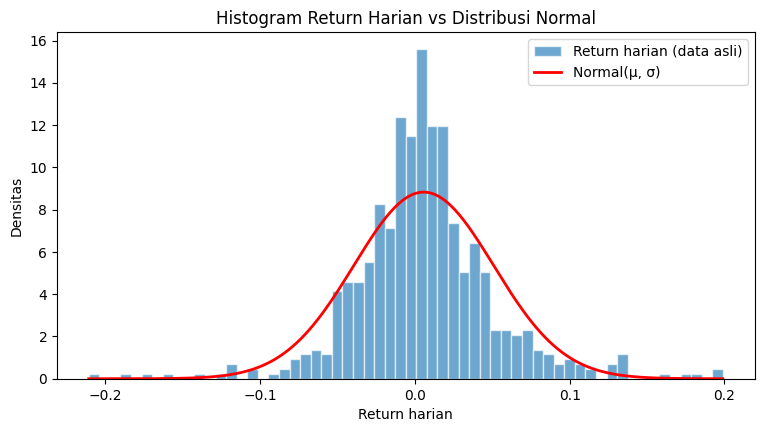

D'Agostino normality test: p-value = 2.208e-14


In [4]:
mu    = ret.mean()
sigma = ret.std()
S0    = df[PRICE_COL].iloc[-1]       # harga terakhir sebagai titik awal simulasi

print(f"Mean harian (μ)       : {mu:.6f}")
print(f"Std dev harian (σ)    : {sigma:.6f}")
print(f"Harga terakhir (S0)   : {S0:,.2f}")
print(f"Skewness              : {stats.skew(ret):.4f}")
print(f"Excess kurtosis       : {stats.kurtosis(ret):.4f}")

plt.figure(figsize=(9,4.5))
plt.hist(ret, bins=60, density=True, alpha=0.65, edgecolor="white", label="Return harian (data asli)")
x = np.linspace(ret.min(), ret.max(), 300)
plt.plot(x, stats.norm.pdf(x, mu, sigma), "r-", lw=2, label="Normal(μ, σ)")
plt.title("Histogram Return Harian vs Distribusi Normal")
plt.xlabel("Return harian"); plt.ylabel("Densitas"); plt.legend(); plt.show()

# Uji kenormalan (informasi untuk justifikasi pemilihan distribusi)
stat, p = stats.normaltest(ret)
print(f"D'Agostino normality test: p-value = {p:.4g}")

**Interpretasi distribusi:** bentuk histogram mendekati lonceng sehingga distribusi **Normal** dipakai sebagai pendekatan (return harian saham umumnya berekor lebih tebal dari Normal; ini menjadi keterbatasan model).

## 5. Simulasi Monte Carlo
Model: $P_t = P_{t-1}\times(1+r_t)$, dengan $r_t \sim \mathcal{N}(\mu,\sigma)$.

In [5]:
rng = np.random.default_rng(NIM)

# Matriks return acak: N_SIM jalur x HORIZON hari
rand_ret = rng.normal(mu, sigma, size=(N_SIM, HORIZON))

# Jalur harga (kumulatif)
paths = S0 * np.cumprod(1 + rand_ret, axis=1)
paths = np.hstack([np.full((N_SIM, 1), S0), paths])   # sisipkan hari ke-0
final_prices = paths[:, -1]

print(f"Jumlah skenario : {N_SIM:,}")
print(f"Harga akhir rata-rata : {final_prices.mean():,.2f}")

Jumlah skenario : 10,000
Harga akhir rata-rata : 1,159.05


## 6. Analisis Risiko

In [6]:
level = S0 * (1 - DROP_THRESH)

p_drop_end = np.mean(final_prices <= level)          # turun >10% pada hari ke-30
p_drop_any = np.mean(paths.min(axis=1) <= level)     # sempat turun >10% kapan saja
se = np.sqrt(p_drop_end * (1 - p_drop_end) / N_SIM)
var95 = np.percentile(final_prices, 5)

print(f"Batas risiko (turun {DROP_THRESH:.0%})         : {level:,.2f}")
print(f"P(turun > {DROP_THRESH:.0%} pada hari ke-{HORIZON})  : {p_drop_end:.2%}")
print(f"   95% CI                              : [{max(0,p_drop_end-1.96*se):.2%}, {min(1,p_drop_end+1.96*se):.2%}]")
print(f"P(sempat turun > {DROP_THRESH:.0%} kapan saja)    : {p_drop_any:.2%}")
print(f"Persentil 5% harga akhir (VaR 95%)     : {var95:,.2f}")
print(f"Potensi kerugian maks. pada VaR 95%    : {(S0-var95)/S0:.2%}")

Batas risiko (turun 10%)         : 878.34
P(turun > 10% pada hari ke-30)  : 15.86%
   95% CI                              : [15.14%, 16.58%]
P(sempat turun > 10% kapan saja)    : 41.50%
Persentil 5% harga akhir (VaR 95%)     : 743.77
Potensi kerugian maks. pada VaR 95%    : 23.79%


## 7. Visualisasi Hasil

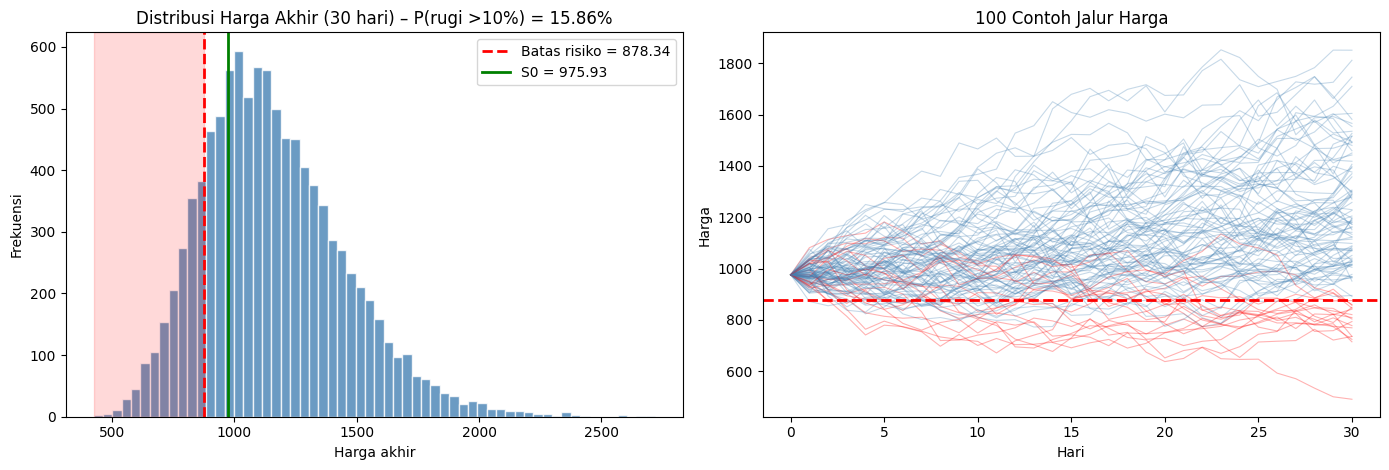

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))

# Histogram harga akhir + threshold
ax[0].hist(final_prices, bins=60, color="steelblue", alpha=0.8, edgecolor="white")
ax[0].axvline(level, color="red", ls="--", lw=2, label=f"Batas risiko = {level:,.2f}")
ax[0].axvline(S0, color="green", lw=2, label=f"S0 = {S0:,.2f}")
ax[0].axvspan(final_prices.min(), level, color="red", alpha=0.15)
ax[0].set_title(f"Distribusi Harga Akhir ({HORIZON} hari) – P(rugi >{DROP_THRESH:.0%}) = {p_drop_end:.2%}")
ax[0].set_xlabel("Harga akhir"); ax[0].set_ylabel("Frekuensi"); ax[0].legend()

# 100 jalur contoh
for i in range(100):
    c = "red" if paths[i, -1] <= level else "steelblue"
    ax[1].plot(paths[i], color=c, alpha=0.3, lw=0.8)
ax[1].axhline(level, color="red", ls="--", lw=2)
ax[1].set_title("100 Contoh Jalur Harga"); ax[1].set_xlabel("Hari"); ax[1].set_ylabel("Harga")
plt.tight_layout(); plt.show()

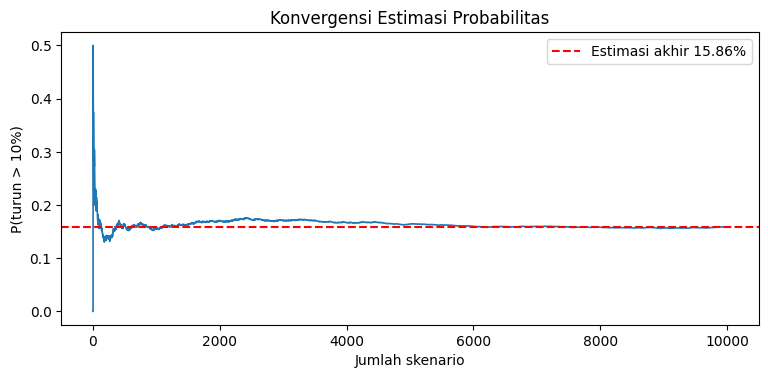

In [8]:
# Konvergensi estimasi probabilitas (Hukum Bilangan Besar)
hit = (final_prices <= level).astype(float)
running = np.cumsum(hit) / np.arange(1, N_SIM + 1)
plt.figure(figsize=(9,3.8))
plt.plot(running, lw=1.2)
plt.axhline(p_drop_end, color="red", ls="--", label=f"Estimasi akhir {p_drop_end:.2%}")
plt.title("Konvergensi Estimasi Probabilitas"); plt.xlabel("Jumlah skenario"); plt.ylabel("P(turun > 10%)")
plt.legend(); plt.show()

## 8. Kesimpulan

In [9]:
print(f'''Berdasarkan {N_SIM:,} skenario Monte Carlo dengan μ={mu:.6f} dan σ={sigma:.6f},
probabilitas harga saham turun lebih dari {DROP_THRESH:.0%} dalam {HORIZON} hari ke depan adalah {p_drop_end:.2%}.
Dengan keyakinan 95%, harga akhir tidak jatuh di bawah {var95:,.2f}.

Keterbatasan: return diasumsikan Normal dan independen antarhari (tanpa volatility clustering
dan tanpa ekor tebal), sehingga risiko kejadian ekstrem dapat diremehkan.''')

Berdasarkan 10,000 skenario Monte Carlo dengan μ=0.005741 dan σ=0.045187,
probabilitas harga saham turun lebih dari 10% dalam 30 hari ke depan adalah 15.86%.
Dengan keyakinan 95%, harga akhir tidak jatuh di bawah 743.77.

Keterbatasan: return diasumsikan Normal dan independen antarhari (tanpa volatility clustering
dan tanpa ekor tebal), sehingga risiko kejadian ekstrem dapat diremehkan.
